# Data Preparation for Association Rule Mining

**Owner:** Arun N / ArunN2005. **Review:** 2. **Issue:** #30.

Prepare one transaction per zone-hour from the existing `features.csv`. This notebook
runs the reusable preparation script, shows bin/cluster evidence, exports readiness
charts and checks the saved files. Mining and rule evaluation follow in #31?#33.

[Complete method and handoff](../data/dataset-documents/association_rule_preparation.md).
The retained dataset starts on 8 Sep 2025. The official model split applies unchanged.
Fit thresholds and clusters on training only, then freeze them for the held-out test period.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/association_rule_data_preparation.py').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
import association_rule_data_preparation as arm

source, split = arm.load_inputs()
display(split)
print(f'{len(source):,} source zone-hours; {source.PULocationID.nunique()} zones')
print('No raw-trip download is needed.')

,dataset,start,end,rows,timestamps
0,train,2025-09-08 00:00:00,2026-01-25 03:00:00,460920,3340
1,test,2026-01-25 04:00:00,2026-02-28 23:00:00,115368,836


576,288 source zone-hours; 138 zones
No raw-trip download is needed.


## 1. Fit the preparation on training history

The source grid, counts, flags and split are checked first. Demand classes use each
zone's training count terciles, including zeros. Equal values stay in the same class.
Temperature terciles use active training zone-hours. Refit k=3 weekly-shape clusters
on nonholiday active training rows, rather than reusing full-period EDA clusters.

Active means >=1 pickup/hour on non-DST training history. All source rows remain in
an audit. The default matrices exclude sparse zones and the combined DST hour, while
retaining ordinary zero-pickup hours in active zones. Rain and snow can both be present.

In [2]:
audit_rows, parameters, checks = arm.prepare()
OUT = arm.OUTPUT
print('Frozen temperature cutoffs (C):', parameters['temperature_cuts_c'])
print('Fit ends:', parameters['fit_end'])
display(pd.read_csv(OUT / 'arm_row_audit.csv'))
display(pd.read_csv(OUT / 'arm_zone_thresholds.csv').head(8))
display(pd.read_csv(OUT / 'arm_item_catalog.csv'))

train: 320,544 transactions, 24 items, 96 active zones


test: 80,256 transactions, 24 items, 96 active zones


Audit: 576,288 original rows retained. 29 saved-file checks pass.


Frozen temperature cutoffs (C): [-0.9, 9.9]
Fit ends: 2026-01-25 03:00:00


,split,exclusion_reason,rows,zones,pickups
0,test,none,80256,96,3870363
1,test,train_mean_below_1,35112,42,16658
2,train,dst_merged_hour,138,138,9166
3,train,none,320544,96,17775327
4,train,train_mean_below_1,140238,42,56603


,PULocationID,train_hours,train_mean,train_zero_share,q_low,q_high,distinct_counts,active,tied_thresholds,zone_cluster,Borough,Zone,service_zone
0,2,3339,0.007787,0.992513,0.0,0.0,3,False,True,near_empty,Queens,Jamaica Bay,Boro Zone
1,4,3339,20.861336,0.003594,12.0,21.0,127,True,False,nightlife,Manhattan,Alphabet City,Yellow Zone
2,7,3339,12.770291,0.004492,9.0,14.0,63,True,False,morning_commute,Queens,Astoria,Boro Zone
3,8,3339,0.077269,0.927224,0.0,0.0,4,False,True,near_empty,Queens,Astoria Park,Boro Zone
4,9,3339,0.238694,0.803833,0.0,0.0,5,False,True,near_empty,Queens,Auburndale,Boro Zone
5,10,3339,2.567236,0.174304,1.0,3.0,18,True,False,morning_commute,Queens,Baisley Park,Boro Zone
6,12,3339,1.499251,0.502546,0.0,1.0,19,True,False,daytime,Manhattan,Battery Park,Yellow Zone
7,13,3339,34.541779,0.043726,14.0,45.0,135,True,False,daytime,Manhattan,Battery Park City,Yellow Zone


,column_index,item,family,value,role
0,0,time_band=late_night,time_band,late_night,antecedent
1,1,time_band=early_morning,time_band,early_morning,antecedent
2,2,time_band=am_rush,time_band,am_rush,antecedent
3,3,time_band=midday,time_band,midday,antecedent
4,4,time_band=pm_rush,time_band,pm_rush,antecedent
5,5,time_band=evening,time_band,evening,antecedent
6,6,day_type=weekday,day_type,weekday,antecedent
7,7,day_type=weekend,day_type,weekend,antecedent
8,8,holiday=regular,holiday,regular,antecedent
9,9,holiday=federal,holiday,federal,antecedent


## 2. Load the exact inputs for the mining member

Each row has one item from each of eight families. The loader returns a Boolean sparse
pandas table and metadata with matching transaction-ID indices. IDs, raw counts, lagged
demand, predictions and other metadata do not become antecedent items.

Use the training table for rule discovery. Later rules must have one `demand=` consequent
and no `demand=` antecedent. Reserve the test table for stability evaluation. The item
catalog records the roles; the mining member must apply the consequent filter.

In [3]:
X_train, train_rows = arm.load_transactions('train')
X_test, test_rows = arm.load_transactions('test')
assert X_train.index.equals(train_rows.index)
assert X_test.index.equals(test_rows.index)
assert X_train.columns.equals(X_test.columns)
print('Training matrix:', X_train.shape)
print('Test matrix:', X_test.shape)
print('Boolean sparse dtype:', X_train.dtypes.iloc[0])
print('Example transaction:', train_rows.transaction_id.iloc[0])
print('Items:', X_train.columns[X_train.iloc[0].to_numpy()].tolist())
display(train_rows[['PULocationID', 'pickup_hour', 'trip_count', 'time_band', 'zone_cluster', 'demand']].head(5))

Training matrix: (320544, 24)
Test matrix: (80256, 24)
Boolean sparse dtype: Sparse[bool, False]
Example transaction: 4@2025-09-08T00:00:00
Items: ['time_band=late_night', 'day_type=weekday', 'holiday=regular', 'rain=no', 'snow=no', 'temperature=upper', 'zone_cluster=nightlife', 'demand=Low']


,PULocationID,pickup_hour,trip_count,time_band,zone_cluster,demand
transaction_id,,,,,,
4@2025-09-08T00:00:00,4,2025-09-08,2,late_night,nightlife,Low
7@2025-09-08T00:00:00,7,2025-09-08,11,late_night,morning_commute,Medium
10@2025-09-08T00:00:00,10,2025-09-08,2,late_night,morning_commute,Medium
12@2025-09-08T00:00:00,12,2025-09-08,0,late_night,daytime,Low
13@2025-09-08T00:00:00,13,2025-09-08,3,late_night,daytime,Low


## 3. Item frequencies, demand balance and threshold evidence

Support below is the fraction of eligible zone-hour transactions containing an item.
It is not a share of taxi trips or independent weather events. Each family sums to 100%.
Zero support for `zone_cluster=near_empty` is expected in the default active population.
Training/test differences are reported without refitting bins on test data.

Snow is rare in training, so the next member should use item frequencies to choose and
record suitable minimum-support thresholds. No frequent itemsets or rules are mined here.

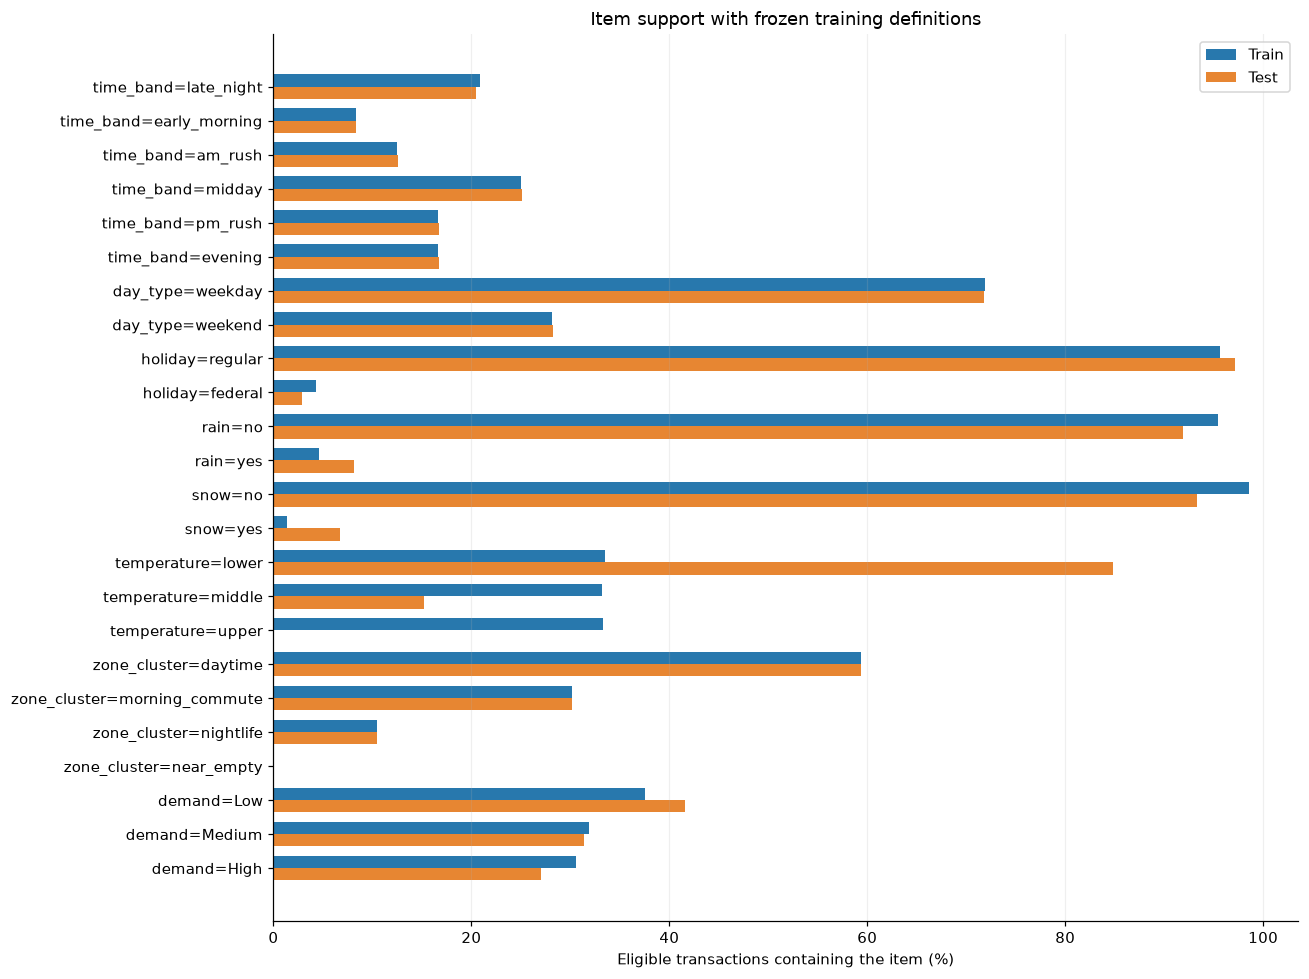

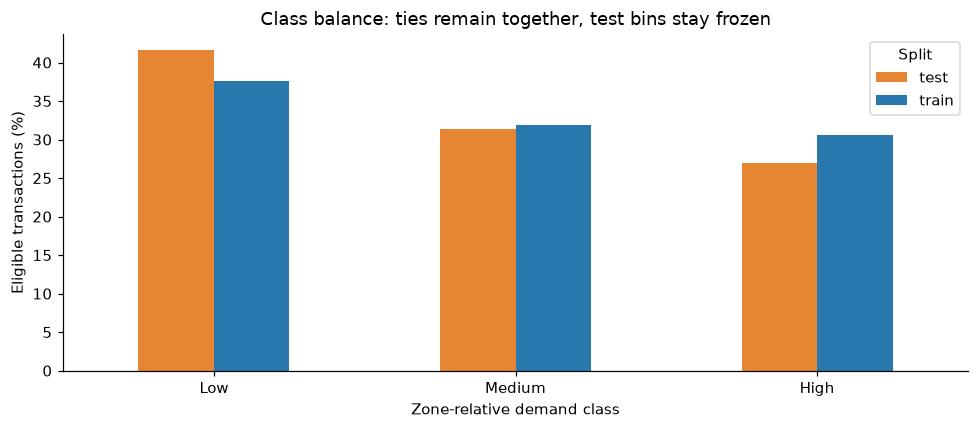

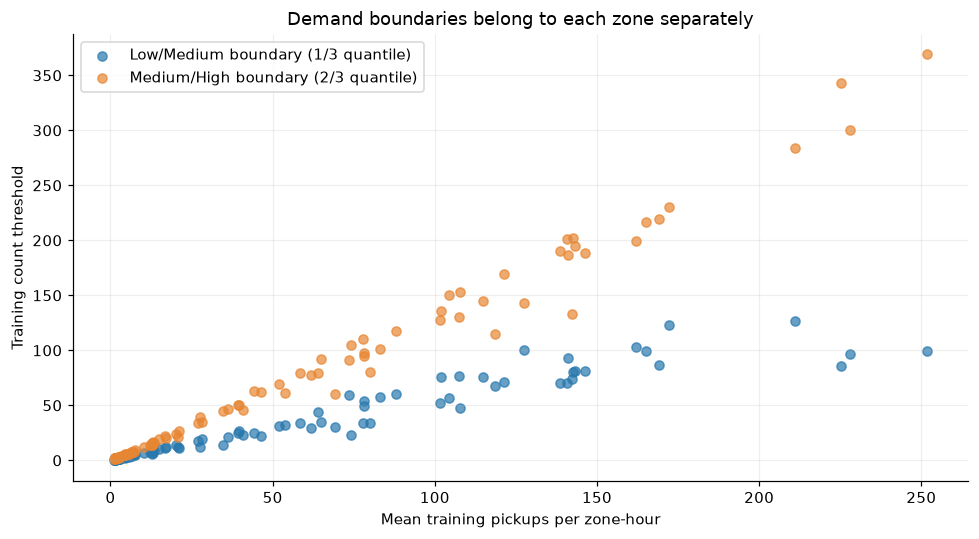

,split,item,count_transactions,support
11,train,rain=yes,14659,0.045732
13,train,snow=yes,4520,0.014101
21,train,demand=Low,120440,0.375736
22,train,demand=Medium,102251,0.318992
23,train,demand=High,97853,0.305272
35,test,rain=yes,6502,0.081016
37,test,snow=yes,5378,0.067011
45,test,demand=Low,33387,0.416006
46,test,demand=Medium,25193,0.313908
47,test,demand=High,21676,0.270086


In [4]:
FIG = ROOT / 'ARM_doc/figures'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False})
freq = pd.read_csv(OUT / 'arm_item_frequencies.csv')
catalog = pd.read_csv(OUT / 'arm_item_catalog.csv')
support = freq.pivot(index='item', columns='split', values='support').reindex(catalog['item'])
fig, ax = plt.subplots(figsize=(12, 9))
y = np.arange(len(support))
ax.barh(y-.18, support['train']*100, height=.36, label='Train', color='#2878ad')
ax.barh(y+.18, support['test']*100, height=.36, label='Test', color='#e78632')
ax.set_yticks(y, support.index)
ax.invert_yaxis()
ax.set(xlabel='Eligible transactions containing the item (%)', title='Item support with frozen training definitions')
ax.legend(); ax.grid(axis='x', alpha=.2)
fig.tight_layout(); fig.savefig(FIG / 'arm_item_support.png', bbox_inches='tight'); plt.show()

classes = freq.loc[freq.family.eq('demand')].pivot(index='value', columns='split', values='support').reindex(['Low', 'Medium', 'High'])*100
fig, ax = plt.subplots(figsize=(9, 4))
classes.plot.bar(ax=ax, color=['#e78632', '#2878ad'], rot=0)
ax.set(ylabel='Eligible transactions (%)', xlabel='Zone-relative demand class', title='Class balance: ties remain together, test bins stay frozen')
ax.legend(title='Split'); fig.tight_layout()
fig.savefig(FIG / 'arm_demand_class_balance.png', bbox_inches='tight'); plt.show()

thresholds = pd.read_csv(OUT / 'arm_zone_thresholds.csv')
active = thresholds.loc[thresholds.active]
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(active.train_mean, active.q_low, label='Low/Medium boundary (1/3 quantile)', color='#2878ad', alpha=.7)
ax.scatter(active.train_mean, active.q_high, label='Medium/High boundary (2/3 quantile)', color='#e78632', alpha=.7)
ax.set(xlabel='Mean training pickups per zone-hour', ylabel='Training count threshold', title='Demand boundaries belong to each zone separately')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(FIG / 'arm_zone_thresholds.png', bbox_inches='tight'); plt.show()

display(freq.loc[freq['item'].isin(['rain=yes', 'snow=yes', 'demand=Low', 'demand=Medium', 'demand=High']), ['split', 'item', 'count_transactions', 'support']])

## 4. Saved-file verification and handoff

Validate source fingerprints, full audit coverage, saved matrix/row/column alignment,
frozen bins, eligible rows, zeros, family exclusivity, frequencies and chronology.
The separate unit tests stress holdout independence, DST, ties, category boundaries
and exact Boolean decoding. Run `python -m unittest discover -s tests -v`.

Mine on training only and evaluate chosen rules on the unchanged test table. Report
support denominators and avoid causal claims. Shared weather cells and adjacent hours
create dependence; the rows are not independent repeated experiments.

In [5]:
checks = arm.validate_artifacts()
display(checks)
assert checks.passed.all()
print(f'All {len(checks)} saved-file checks passed.')
print('Preparation complete. Frequent itemsets and rules are the next stage.')
display(Markdown('[Method, output schemas and mining handoff](../data/dataset-documents/association_rule_preparation.md)'))

,check,passed,detail
0,Unchanged input: data/processed/features.csv,True,SHA-256
1,Unchanged input: data/raw/taxi_zones_manhattan...,True,SHA-256
2,Unchanged input: models/modeling/split_summary...,True,SHA-256
3,Complete audit grid,True,576288
4,Audit transaction IDs,True,576288
5,Audit missing values,True,all fields
6,Frozen parameter scope,True,2026-01-25 03:00:00
7,Catalog roles,True,demand kept out of antecedents
8,Unique items,True,24
9,Metadata excluded from items,True,"no raw counts, lags, IDs or predictions"


All 29 saved-file checks passed.
Preparation complete. Frequent itemsets and rules are the next stage.


[Method, output schemas and mining handoff](../data/dataset-documents/association_rule_preparation.md)